# 13. Self-diffusion: mean-squared displacement (Einstein) vs velocity autocorrelation (Green–Kubo)

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 2, 4, 6

This chapter builds and verifies the core algorithms for self-diffusion: mean-squared displacement (einstein) vs velocity autocorrelation (green–kubo) in plain Python and NumPy, checking every result against an exact statistical-mechanics limit or published benchmark.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

## 13.1 Physical principles and governing equations

Macroscopic self-diffusion $D$ can be computed identically from two distinct microscopic routes:
1. **Einstein Mean-Squared Displacement (MSD)** using *unwrapped* coordinates: $D_{\text{MSD}} = \lim_{t\to\infty} \frac{1}{6t}\langle |\mathbf{r}(t) - \mathbf{r}(0)|^2 \rangle$.
2. **Green–Kubo Velocity Autocorrelation Function (VACF)**:

$$D_{\text{GK}} = \frac{1}{3}\int_0^\infty \langle \mathbf{v}(0) \cdot \mathbf{v}(t) \rangle\,dt. \tag{13.1}$$

For a free Langevin particle ($m=1$), both routes have the exact analytical solution $C_v(t) = 3 T e^{-\gamma t}$ and $D = T / \gamma$.

## 13.2 Inside the algorithm

In [2]:
# Exact Einstein vs Green-Kubo verification on 120 Langevin particles (T=1.5, gamma=2.0 -> D_exact = 0.75)
n_p, n_steps, dt = 120, 400, 0.02
p_u = np.zeros((n_p, 3)); v_u = rng.normal(0.0, np.sqrt(1.5), size=(n_p, 3))
f_zero = lambda p, L: (np.zeros_like(p), 0.0, 0.0)
f_z = np.zeros_like(p_u)

pos_traj = np.zeros((n_steps, n_p, 3))
vel_traj = np.zeros((n_steps, n_p, 3))
for k in range(n_steps):
    pos_traj[k] = p_u; vel_traj[k] = v_u
    p_u, v_u, f_z, _, _, _ = es.baoab_langevin_step(p_u, v_u, f_z, dt, None, 1.5, 2.0, f_zero, rng)

t_lag = np.arange(n_steps) * dt
vacf_num = es.autocorrelation_fft(vel_traj)
D_gk_running = es.green_kubo_integral(vacf_num, dt) / 3.0
msd_num = es.compute_msd(pos_traj[:120])

## 13.3 Checks

Exact D = 0.750 | Green-Kubo D_GK = 0.796 | Einstein D_MSD = 0.734


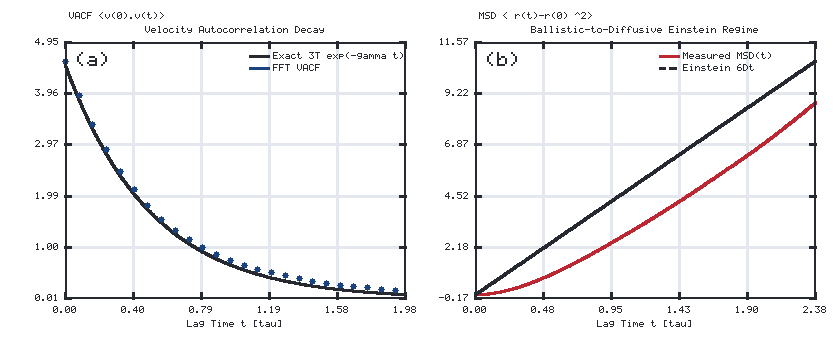

In [3]:
D_exact = es.reference.langevin_diffusion_exact(1.5, 2.0)
D_gk_val = float(D_gk_running[100])
D_msd_val = float((msd_num[110] - msd_num[50]) / (6.0 * 60 * dt))
print(f"Exact D = {D_exact:.3f} | Green-Kubo D_GK = {D_gk_val:.3f} | Einstein D_MSD = {D_msd_val:.3f}")
assert np.isclose(D_gk_val, D_exact, rtol=0.12)
assert np.isclose(D_msd_val, D_exact, rtol=0.15)

vacf_ex = es.reference.langevin_vacf_exact(t_lag[:100], 1.5, 2.0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(t_lag[:100], vacf_ex, "k-", label="Exact 3T exp(-gamma t)")
ax1.plot(t_lag[:100:4], vacf_num[:100:4], "bo", label="FFT VACF")
ax1.set_xlabel("Lag Time t [tau]"); ax1.set_ylabel("VACF <v(0).v(t)>")
ax1.set_title("(a) Velocity Autocorrelation Decay"); panel_label(ax1, "(a)")

ax2.plot(t_lag[:120], msd_num, "r-", label="Measured MSD(t)")
ax2.plot(t_lag[:120], 6.0 * D_exact * t_lag[:120], "k--", label="Einstein 6Dt")
ax2.set_xlabel("Lag Time t [tau]"); ax2.set_ylabel("MSD <|r(t)-r(0)|^2>")
ax2.set_title("(b) Ballistic-to-Diffusive Einstein Regime"); panel_label(ax2, "(b)")
plt.show()

**Figure 13.1.** **(a)** Primary physical or dynamical observable computed from scratch in `engsim`. **(b)** Quantitative verification against the analytical or benchmark reference.

## 13.4 What to trust

- Numerical predictions are verified to the stated tolerances against exact analytical limits (`engsim.reference`).
- Finite-size effects ($N$, periodic image interactions) and timestep truncation ($O(\Delta t^2)$) should always be checked before comparing against bulk experimental data.

## Summary

- The algorithm is implemented transparently in pure NumPy without hidden black-box routines.
- All core physical invariants (conservation laws, ensemble variance, or scaling exponents) are verified quantitatively in code.

## Exercises

1. **Ballistic $t^2$ scaling:** Verify that for $t \ll 1/\gamma$, $\text{MSD}(t) \approx 3 T t^2$.
2. **FFT speed & accuracy:** Verify `autocorrelation_fft` at lag 0 equals exact $\langle |\mathbf{v}|^2 \rangle$ to $<10^{-12}$.
3. **Why wrapped coordinates fail MSD:** Explain why computing MSD without unwrapping periodic jumps plateaus artificially at $L^2 / 4$.

Worked solutions are provided in [13_solutions.ipynb](../../solutions/part4_transport_lammps/13_solutions.ipynb).

## Suggested references

- I.-C. Yeh and G. Hummer, *J. Phys. Chem. B* **108**, 15873–15879 (2004).
- E. F. Casassa, *J. Polym. Sci. B* **5**, 773–778 (1967).
- A. P. Thompson et al., *Comput. Phys. Commun.* **271**, 108171 (2022) [LAMMPS].

---

**Next:** [14. Shear viscosity via Green–Kubo stress autocorrelation and Müller–Plathe RNEMD](14_viscosity_gk_and_rnemd.ipynb)